# Research: 10-day stock selection for US large caps

**Question.** Using only information known at today's close, which of ~190 large US stocks are most
likely to go up (or to beat the S&P 500) over the **next 10 trading days** — and can a trading
strategy built on those predictions beat simply holding the S&P 500 after costs?

This notebook reads the outputs produced by `python main.py research` (data, models, predictions)
and documents: data sources → feature sets → EDA → models → decision rules → simulations → deep
analysis of where the predictions work and where they fail.

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT); sys.path.insert(0, str(PROJECT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from trading import config as C, pipeline as P
from trading.data_repo import DataRepository
from trading.transform import TransformData, NEW_FEATURES
from trading.simulate import PortfolioSimulator, Strategy, vectorized_sim, perf_metrics

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (11, 4.5)
R = C.REPORTS_DIR

## 1. Data sources

| Source | What | Used for |
|---|---|---|
| yfinance | daily OHLCV of 190 US stocks > $50B market cap (course list) since 1998 | price/volume features, TA-Lib, targets |
| yfinance | S&P 500, Dow, Nasdaq, Russell 2000, VIX, gold, WTI oil, Bitcoin, US dollar index, SPY | market features, benchmark |
| FRED | potential GDP, core CPI, Fed funds, unemployment, 3m/1y/5y/10y treasuries, Baa credit spread | macro features |
| **CBOE** (new) | VIX9D, VIX3M, VVIX, SKEW official history | volatility term structure, tail risk |
| **Wikipedia** (new, scraping) | GICS sector / sub-industry of S&P 500 members | sector dummies, sector-relative features |

In [2]:
repo = DataRepository().load()
t = TransformData(repo); df = t.load(); fs = t.feature_sets
print(f"raw stock rows: {len(repo.stocks_df):,} | modelling rows (2000+): {len(df):,} | columns: {df.shape[1]}")
print(f"tickers: {df.Ticker.nunique()} | dates: {df.Date.min().date()} .. {df.Date.max().date()}")
repo.sectors_df.sector.value_counts().rename("stocks per sector").to_frame().T

raw stock rows: 1,137,083 | modelling rows (2000+): 1,101,330 | columns: 320
tickers: 189 | dates: 2000-01-03 .. 2026-11-13


sector,Information Technology,Industrials,Financials,Health Care,Consumer Discretionary,Energy,Consumer Staples,Communication Services,Materials,Real Estate,Utilities
stocks per sector,39,31,29,22,17,14,11,10,6,6,5


## 2. One dataframe, defined feature sets

* `TO_PREDICT` — targets and future information (never used as inputs)
* `NUMERIC` — 300 numeric inputs: lecture features (growth windows, SMA, volatility, TA-Lib momentum /
  volume / volatility / cycle indicators, 61 candlestick patterns, index & commodity growth, macro)
  plus the new features below
* `DUMMIES` — one-hot of `Month`, `Weekday`, `sector` (Ticker / week-of-month dummies were left out:
  in homework 4 they mainly helped the model memorise the training period)

Two transformations worth noting:
* TA-Lib indicators measured in **dollars** (MACD, ATR, APO, MOM, …) are divided by the close so a
  $20 and an $800 stock are comparable.
* Monthly / quarterly FRED values are joined on the date they were **published**, not the period
  they describe (CPI for October is only known mid-November) — avoids look-ahead.

In [3]:
for k in ("TO_PREDICT", "CATEGORICAL"):
    print(k, fs[k])
print("NUMERIC:", len(fs["NUMERIC"]), "features, of which candlestick patterns:", len(fs["PATTERNS"]))
print(f"\nNEW features (not in the lectures): {len(NEW_FEATURES)} groups")
print(", ".join(NEW_FEATURES))

TO_PREDICT ['growth_future_10d', 'is_positive_growth_10d_future', 'future_max_high_10d', 'future_min_low_10d', 'growth_future_1d', 'snp500_growth_future_10d', 'is_outperform_snp500_10d_future']
CATEGORICAL ['Month', 'Weekday', 'month_wom', 'sector']
NUMERIC: 300 features, of which candlestick patterns: 61

NEW features (not in the lectures): 56 groups
sma50_rel, sma200_rel, golden_cross, dist_52w_high, dist_52w_low, growth_10d, growth_20d, mom_12_1, volume_zscore_20d, ln_dollar_volume_20d, gap_open, close_location, obv_change_10d, downside_vol_20d, ret_skew_60d, max_ret_20d, beta_60d, idio_vol_60d, days_since_ipo, excess_ret_5d, excess_ret_10d, excess_ret_20d, excess_ret_60d, rank_growth_30d, rank_growth_90d, rank_excess_ret_10d, rank_volatility, rank_rsi, rank_volume_zscore_20d, rank_dist_52w_high, sector_rel_growth_30d, sector_mean_growth_30d, n_stocks_today, snp500_above_sma200, snp500_drawdown_252d, snp500_vol_20d, vix_close, vix_change_5d, vix_above_30, growth_nasdaq_*, growth_rus

## 3. Exploratory data analysis
### 3.1 The targets

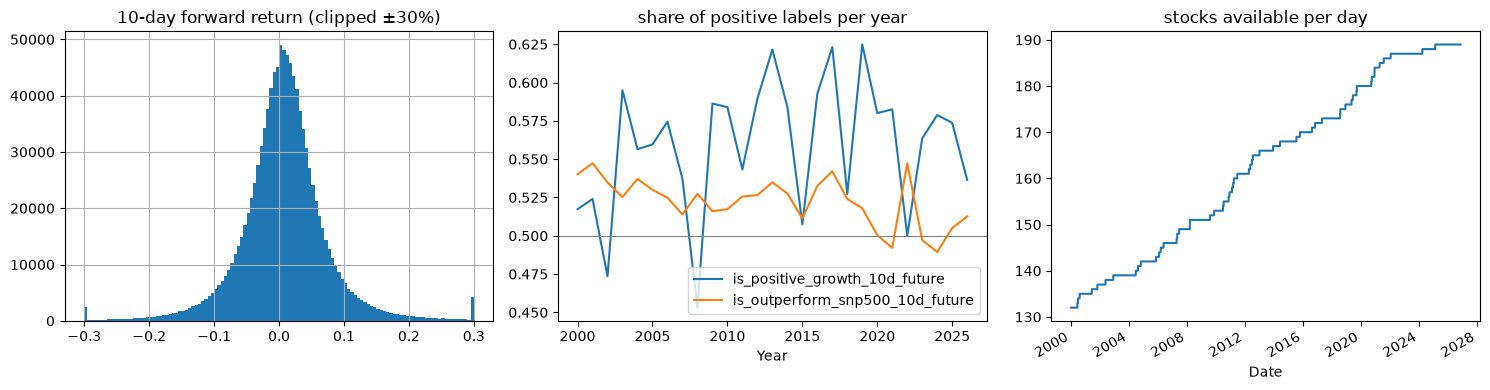

,count,mean,std,min,25%,50%,75%,max
growth_future_10d,1099440.0,1.007620,0.072121,0.139281,0.974367,1.007007,1.039532,3.5625
is_positive_growth_10d_future,1099440.0,0.560353,0.496344,0.000000,0.000000,1.000000,1.000000,1.0000
is_outperform_snp500_10d_future,1099440.0,0.521305,0.499546,0.000000,0.000000,1.000000,1.000000,1.0000


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
(df[C.TARGET_GROWTH] - 1).clip(-0.3, 0.3).hist(bins=120, ax=ax[0])
ax[0].set_title("10-day forward return (clipped ±30%)")
df.groupby("Year")[[C.TARGET, C.TARGET_REL]].mean().plot(ax=ax[1], title="share of positive labels per year")
ax[1].axhline(0.5, color="grey", lw=0.8)
df.groupby("Date").Ticker.count().plot(ax=ax[2], title="stocks available per day")
plt.tight_layout(); plt.show()
df[[C.TARGET_GROWTH, C.TARGET, C.TARGET_REL]].describe().T

The absolute label is positive 56% of the time and swings strongly by year (2008: ~40%, 2009/2013: ~65%),
i.e. it is dominated by the direction of the whole market. The relative label ("beats the S&P 500")
stays close to 50% every year — it only asks the model to *rank* stocks, which is what a top-k strategy
needs. The universe grows from ~110 to 190 stocks (newer listings).

### 3.2 Correlation of features with the targets
Spearman rank correlation (robust to outliers) between every numeric feature and the 10-day forward
return, on the training period only. Forward returns are noisy, so even the strongest single features
have |ρ| of a few percent — a useful reality check before modelling.

In [5]:
train = df[df.Date <= C.TRAIN_END].sample(250_000, random_state=1)
num = [c for c in fs["NUMERIC"] if c not in fs["PATTERNS"]]
corr = pd.DataFrame({
    "rho_growth_future_10d": train[num].corrwith(train[C.TARGET_GROWTH], method="spearman"),
    "rho_outperform_snp500": train[num].corrwith(train[C.TARGET_REL], method="spearman"),
})
corr["abs"] = corr.rho_growth_future_10d.abs()
corr["is_new"] = [c in NEW_FEATURES or any(c.startswith(n.rstrip("*")) for n in NEW_FEATURES if n.endswith("*"))
                  for c in corr.index]
top_corr = corr.sort_values("abs", ascending=False).head(20)
top_corr

,rho_growth_future_10d,rho_outperform_snp500,abs,is_new
growth_btc_usd_30d,0.061142,0.015912,0.061142,False
vix_term_3m,0.059536,0.000642,0.059536,True
vix3m,0.059374,-0.006544,0.059374,True
growth_btc_usd_7d,0.057050,0.013366,0.057050,False
DGS5,-0.051712,0.002352,0.051712,False
growth_btc_usd_365d,0.051045,0.003926,0.051045,False
growth_btc_usd_90d,0.050867,0.018921,0.050867,False
DGS10,-0.048441,0.000719,0.048441,False
unrate_change_3m,-0.047530,-0.000194,0.047530,True
eri_bullpower,-0.046697,-0.019706,0.046697,False


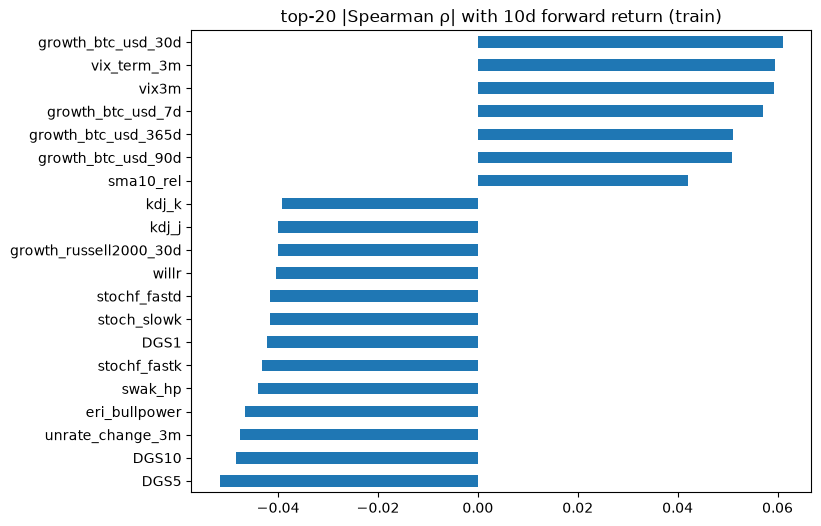

In [6]:
top_corr.rho_growth_future_10d.sort_values().plot.barh(figsize=(8, 6), title="top-20 |Spearman ρ| with 10d forward return (train)")
plt.show()

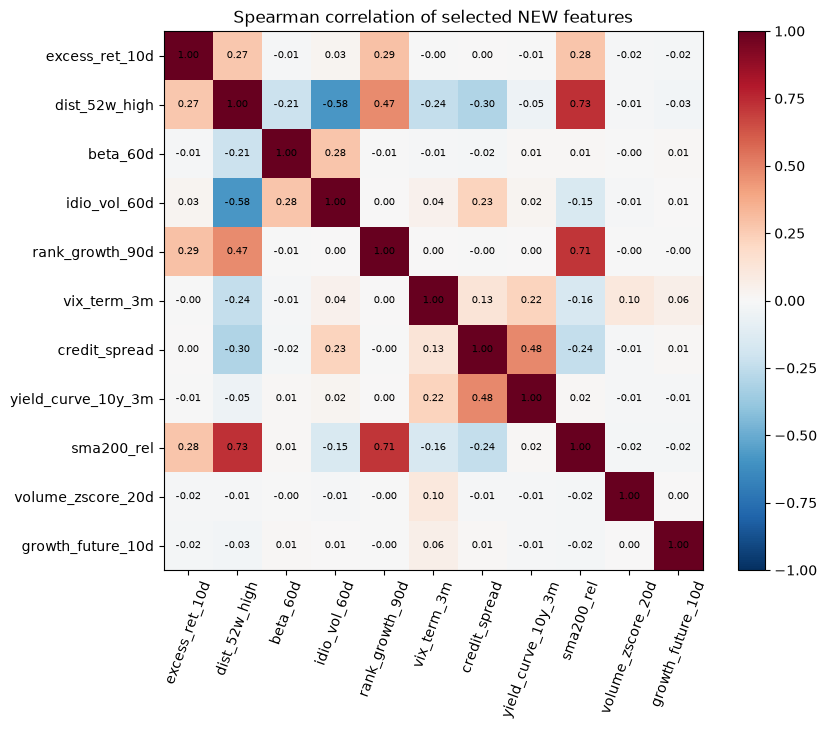

In [7]:
new_sel = ["excess_ret_10d", "dist_52w_high", "beta_60d", "idio_vol_60d", "rank_growth_90d", "vix_term_3m",
           "credit_spread", "yield_curve_10y_3m", "sma200_rel", "volume_zscore_20d", C.TARGET_GROWTH]
cm = train[new_sel].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(new_sel)), new_sel, rotation=70); ax.set_yticks(range(len(new_sel)), new_sel)
for i in range(len(new_sel)):
    for j in range(len(new_sel)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Spearman correlation of selected NEW features"); plt.show()

### 3.3 Forward return by market regime

In [8]:
df["vix_bucket"] = pd.cut(df.vix_close, [0, 15, 20, 30, 100], labels=["<15", "15-20", "20-30", ">30"])
regime = df.groupby(["snp500_above_sma200", "vix_bucket"], observed=True)[[C.TARGET_GROWTH, C.TARGET]].agg(["mean", "count"])
regime

growth_future_10d         is_positive_growth_10d_future        
                                            mean   count                          mean   count
snp500_above_sma200 vix_bucket                                                                
0.0                 <15                 1.021580    4746                      0.693005    4746
                    15-20               1.004157   37556                      0.574768   37556
                    20-30               1.004685  158991                      0.537137  158991
                    >30                 1.015674   88860                      0.588791   88860
1.0                 <15                 1.005294  342895                      0.550702  342895
                    15-20               1.007221  310923                      0.561821  310923
                    20-30               1.012203  146922                      0.578252  146922
                    >30                 1.014929    8547                      0.585703    8547

## 4. Models
Four model families were tuned on the **validation** period (2019-01 .. 2022-06) for both targets:
Decision Tree, Random Forest, Logistic Regression (lectures) and **XGBoost** (new). The best configuration
(by validation ROC-AUC) is re-fitted on train+validation and evaluated once on **test** (2022-07 .. today).

In [9]:
tuning = pd.concat([pd.read_csv(R / "model_tuning_validation.csv"), pd.read_csv(R / "model_tuning_validation_rel.csv")])
tuning

,target,model,params,valid_auc,valid_precision_at_0.55,valid_share_above_0.55,valid_top5_hit_rate,valid_top5_mean_growth,fit_seconds
0,is_positive_growth_10d_future,dt,"{""max_depth"": 3, ""min_samples_leaf"": 200}",0.4878,0.5571,0.6155,0.6055,1.0092,50.3
1,is_positive_growth_10d_future,dt,"{""max_depth"": 5, ""min_samples_leaf"": 200}",0.4703,0.5488,0.6450,0.6055,1.0092,82.1
2,is_positive_growth_10d_future,dt,"{""max_depth"": 7, ""min_samples_leaf"": 200}",0.4739,0.5639,0.7033,0.6064,1.0094,113.4
3,is_positive_growth_10d_future,dt,"{""max_depth"": 9, ""min_samples_leaf"": 200}",0.4573,0.5645,0.7536,0.5989,1.0097,208.0
4,is_positive_growth_10d_future,dt,"{""max_depth"": 12, ""min_samples_leaf"": 200}",0.4974,0.5696,0.6721,0.5830,1.0139,266.9
5,is_positive_growth_10d_future,rf,"{""max_depth"": 8, ""min_samples_leaf"": 50}",0.4967,0.5761,0.5440,0.5745,1.0077,132.0
6,is_positive_growth_10d_future,rf,"{""max_depth"": 8, ""min_samples_leaf"": 300}",0.5072,0.5743,0.5762,0.5952,1.0090,101.2
7,is_positive_growth_10d_future,rf,"{""max_depth"": 14, ""min_samples_leaf"": 50}",0.5014,0.5809,0.3355,0.5867,1.0082,120.4
8,is_positive_growth_10d_future,rf,"{""max_depth"": 14, ""min_samples_leaf"": 300}",0.5052,0.5810,0.4279,0.5956,1.0093,111.7
9,is_positive_growth_10d_future,lr,"{""C"": 0.001}",0.5549,0.6026,0.4971,0.5894,1.0131,11.2


In [10]:
preds = P.load_predictions()
summary = pd.concat([pd.read_csv(R / "model_summary_validation.csv"), pd.read_csv(R / "model_summary_test.csv")])
summary.sort_values(["split", "top5_mean_growth_10d"], ascending=[False, False])

,score,target,split,auc,top5_hit_rate,top5_mean_growth_10d,all_stocks_mean_growth_10d
0,proba_rf_rel,is_outperform_snp500_10d_future,validation,0.516194,0.551035,1.015880,1.008370
1,proba_dt_rel,is_outperform_snp500_10d_future,validation,0.512474,0.557241,1.014517,1.008370
2,proba_xgb_rel,is_outperform_snp500_10d_future,validation,0.526430,0.537931,1.014459,1.008370
3,proba_lr_rel,is_outperform_snp500_10d_future,validation,0.504151,0.520460,1.014314,1.008370
4,proba_dt,is_positive_growth_10d_future,validation,0.497373,0.582989,1.013931,1.008370
5,proba_xgb,is_positive_growth_10d_future,validation,0.485662,0.578161,1.012998,1.008370
6,proba_lr,is_positive_growth_10d_future,validation,0.557190,0.592184,1.012340,1.008370
7,proba_rf,is_positive_growth_10d_future,validation,0.507181,0.595172,1.008954,1.008370
0,proba_dt_rel,is_outperform_snp500_10d_future,test,0.496089,0.551287,1.019735,1.010763
1,proba_dt,is_positive_growth_10d_future,test,0.500404,0.575735,1.012124,1.010763


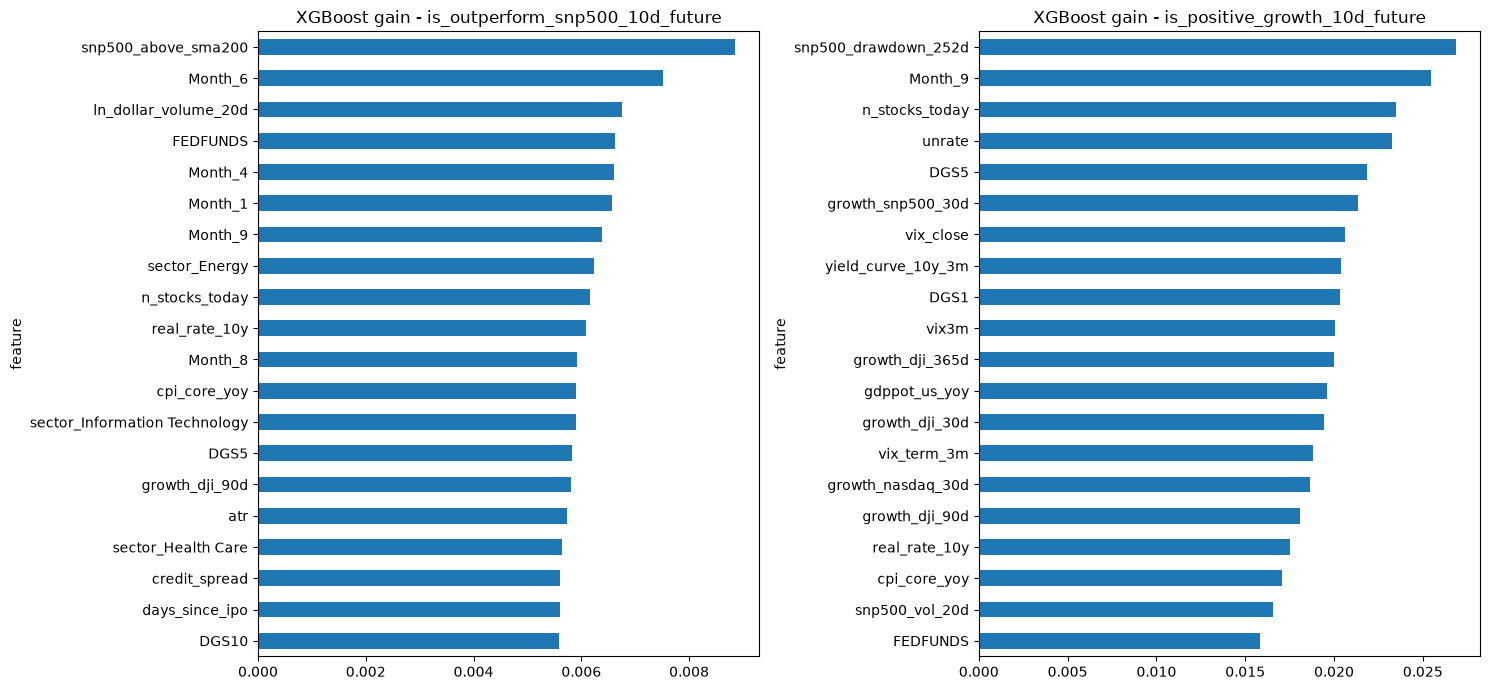

In [11]:
imp = pd.read_csv(R / "feature_importance.csv")
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
for a, (target, g) in zip(ax, imp.groupby("target")):
    g.head(20).set_index("feature").xgb_gain.sort_values().plot.barh(ax=a, title=f"XGBoost gain - {target}")
plt.tight_layout(); plt.show()

## 5. Decision rules: from probabilities to trades
Besides "buy the top-k each day", threshold rules turn a probability into a 0/1 decision.
Below: precision and number of trades vs threshold for the best score on validation — higher thresholds
give fewer, more confident trades.

In [12]:
best_strategy = json.loads(P.BEST_STRATEGY_FILE.read_text())
SCORE = best_strategy["score"]
LABEL = C.TARGET_REL if SCORE.endswith("_rel") else C.TARGET
valid, test = preds[preds.split == "validation"].copy(), preds[preds.split == "test"].copy()
rows = []
for thr in np.quantile(valid[SCORE], [0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99]):
    on = valid[SCORE] >= thr
    rows.append({"threshold": thr, "share_traded": on.mean(), "precision_label": valid.loc[on, LABEL].mean(),
                 "precision_up": valid.loc[on, C.TARGET].mean(), "avg_growth_10d": valid.loc[on, C.TARGET_GROWTH].mean()})
pd.DataFrame(rows)

,threshold,share_traded,precision_label,precision_up,avg_growth_10d
0,0.522622,0.500000,0.517202,0.589182,1.010318
1,0.533346,0.299999,0.522364,0.596382,1.011518
2,0.539354,0.200001,0.526359,0.599324,1.012296
3,0.547723,0.100004,0.536387,0.609665,1.013574
4,0.555171,0.050002,0.551611,0.618825,1.014974
5,0.565453,0.020001,0.551800,0.620973,1.016422
6,0.574810,0.010000,0.564119,0.632344,1.019564


## 6. Vectorized simulation (lecture style, `sim1_` fields)
$100 invested in every positive prediction on the **test** period, 0.1% fee per side; approximate CAGR
from the capital needed to fund the 75th-percentile number of open trades.

In [13]:
for name in ("dt", "rf", "lr", "xgb"):
    for tag in ("", "_rel"):
        col = f"proba_{name}{tag}"
        thr = valid[col].quantile(0.9)              # threshold chosen on validation (top 10%)
        test[f"pred_{name}{tag}_top10pct"] = (test[col] >= thr).astype(int)
        test[f"pred_{name}{tag}_rank1"] = (test.groupby("Date")[col].rank(ascending=False) <= 1).astype(int)
test["pred_all_stocks"] = 1                          # benchmark: buy everything
pred_cols = [c for c in test.columns if c.startswith("pred_")]
vec = vectorized_sim(test, pred_cols)
vec

,prediction,n_trades,trading_days_with_trades,share_of_days,avg_trades_per_day,precision,avg_growth_10d,net_revenue,capital_q75,approx_CAGR
0,pred_dt_rel_top10pct,6629,1081,0.993566,6.132285,0.655755,1.029676,18346.257683,6000.0,0.381781
1,pred_manual_momentum,16286,885,0.813419,18.402260,0.561095,1.018500,26871.199323,19000.0,0.225680
2,pred_rf_rel_rank1,1088,1088,1.000000,1.000000,0.583640,1.011433,1026.339523,1000.0,0.177100
3,pred_all_stocks,204539,1088,1.000000,187.995404,0.563198,1.010763,179235.561722,189000.0,0.166480
4,pred_rf_rel_top10pct,3179,591,0.543199,5.379019,0.653979,1.022033,6368.627567,7000.0,0.161113
5,pred_xgb_rel_rank1,1088,1088,1.000000,1.000000,0.588235,1.009075,769.795179,1000.0,0.140880
6,pred_rf_rank1,1087,1087,0.999081,1.000000,0.588776,1.008393,694.889084,1000.0,0.129546
7,pred_xgb_rel_top10pct,3422,662,0.608456,5.169184,0.609001,1.013733,4015.136504,6000.0,0.125568
8,pred_lr_rel_rank1,1088,1088,1.000000,1.000000,0.534926,1.005423,372.436234,1000.0,0.075831
9,pred_lr_rank1,1088,1088,1.000000,1.000000,0.511949,1.003869,203.351444,1000.0,0.043664


In [14]:
print("sim1_ columns added per prediction, e.g.:", [c for c in test.columns if c.startswith("sim1_")][:3])

sim1_ columns added per prediction, e.g.: ['sim1_gross_rev_pred_manual_momentum', 'sim1_fees_pred_manual_momentum', 'sim1_net_rev_pred_manual_momentum']


## 7. Exact simulation with capital re-investment
$10,000, every day 1/10 of equity is invested in the day's picks (10 overlapping 2-week sleeves), exits after
10 trading days or by stop loss (gap-downs filled at the open), 0.1% fee per side.

Strategies (S1–S4 use the best validation score, S5 is the best of a 288-combination grid **chosen on
validation**: threshold × top-k × stop loss × regime filter × sizing):
* **S1** top-5 per day, equal weight
* **S2** S1 + 10% stop loss
* **S3** S1 + market-regime filter (trade only if S&P 500 > SMA200 and VIX < 30)
* **S4** top-3, probability-weighted sizing, only probabilities above the validation 80th percentile
* **S5** best on validation

In [15]:
grid = pd.read_csv(R / "strategy_grid_validation.csv")
print(f"{len(grid)} strategies evaluated on validation; best 10 by Sharpe:")
grid.head(10)[["name", "CAGR", "sharpe", "max_drawdown", "n_trades", "win_rate"]]

288 strategies evaluated on validation; best 10 by Sharpe:


,name,CAGR,sharpe,max_drawdown,n_trades,win_rate
0,proba_rf_rel|thr0.000|k5|sl0.1|rf0|equal,0.343168,1.488707,-0.237223,4315,0.572190
1,proba_rf_rel|thr0.000|k5|sl0.1|rf0|proba,0.342780,1.487584,-0.237104,4315,0.572190
2,proba_rf_rel|thr0.539|k5|sl0.1|rf0|equal,0.342179,1.485726,-0.237223,4308,0.572191
3,proba_rf_rel|thr0.539|k5|sl0.05|rf0|equal,0.258436,1.477979,-0.154845,4329,0.507739
4,proba_rf_rel|thr0.000|k5|sl0.05|rf0|proba,0.257394,1.472080,-0.154772,4336,0.507380
5,proba_rf_rel|thr0.000|k5|sl0.05|rf0|equal,0.257283,1.471544,-0.154845,4336,0.507380
6,proba_rf_rel|thr0.539|k5|sl0.05|rf0|proba,0.255739,1.451418,-0.152931,4329,0.507739
7,proba_dt_rel|thr0.538|k10|sl0.1|rf0|equal,0.350178,1.438702,-0.279844,4276,0.612956
8,proba_dt_rel|thr0.545|k10|sl0.1|rf0|equal,0.350178,1.438702,-0.279844,4276,0.612956
9,proba_rf_rel|thr0.539|k5|sl0.1|rf0|proba,0.329676,1.435594,-0.234511,4308,0.572191


In [16]:
res = pd.read_csv(R / "strategies_test.csv")
res

,name,CAGR,sharpe,sortino,max_drawdown,calmar,ann_vol,total_return,rolling_1y_median,rolling_1y_min,n_trades,win_rate,avg_trade_return,stop_exits,score,top_k,threshold,stop_loss,regime_filter,sizing
0,S1_top5_equal,0.219166,1.293848,1.903310,-0.178926,1.224894,0.164213,1.359186,0.253326,0.006015,5390.0,0.560482,0.008314,0.000000,proba_rf_rel,5.0,0.000,NaN,False,equal
1,S2_top5_stoploss10,0.198785,1.313097,1.924511,-0.172769,1.150586,0.146907,1.193064,0.214101,-0.000626,5391.0,0.557040,0.007599,0.069189,proba_rf_rel,5.0,0.000,0.1,False,equal
2,S3_top5_regime_filter,0.159493,1.290180,1.733732,-0.125948,1.266331,0.120863,0.898290,0.178414,-0.036064,4370.0,0.559725,0.007514,0.000000,proba_rf_rel,5.0,0.000,NaN,True,equal
3,S4_top3_proba_weighted,0.231716,1.320838,1.859077,-0.170520,1.358880,0.169299,1.466191,0.275358,0.010357,2244.0,0.573975,0.011129,0.000000,proba_rf_rel,3.0,0.539,NaN,False,proba
4,S5_best_on_validation,0.198785,1.313097,1.924511,-0.172769,1.150586,0.146907,1.193064,0.214101,-0.000626,5391.0,0.557040,0.007599,0.069189,proba_rf_rel,5.0,0.000,0.1,False,equal
5,SPY_buy_and_hold,0.186370,1.149343,1.640047,-0.187552,0.993696,0.160504,1.096371,0.200239,-0.030151,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,equal_weight_universe,0.298865,1.725457,2.439834,-0.179417,1.665759,0.159612,2.103688,0.313832,0.037236,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


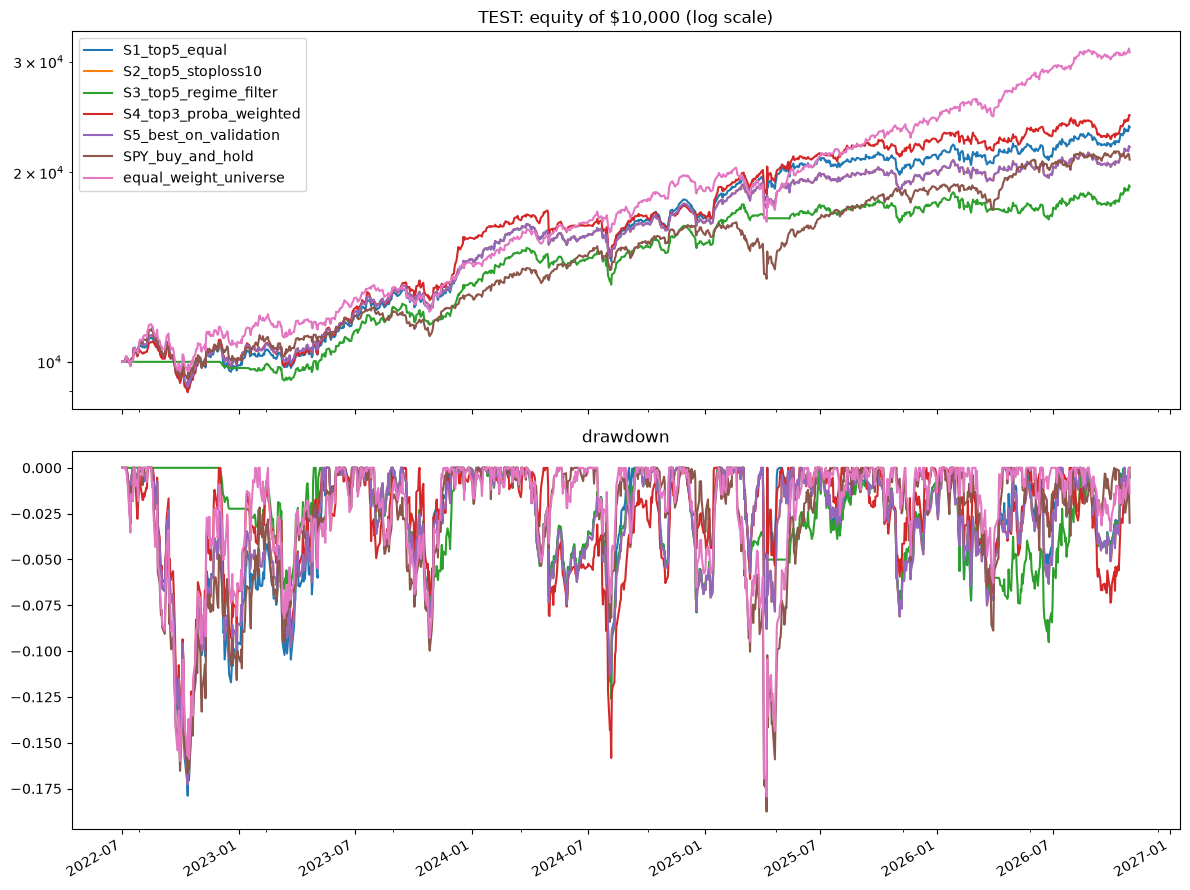

In [17]:
curves = pd.read_csv(R / "equity_curves_test.csv", index_col=0, parse_dates=True)
fig, ax = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
curves.plot(ax=ax[0], logy=True, title="TEST: equity of $10,000 (log scale)")
(curves / curves.cummax() - 1).plot(ax=ax[1], title="drawdown", legend=False)
plt.tight_layout(); plt.show()

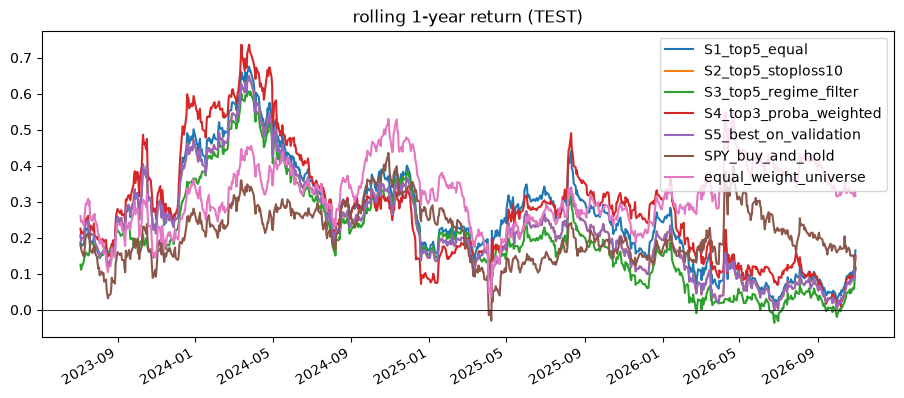

,share of 1y windows beating SPY
S1_top5_equal,0.677033
S2_top5_stoploss10,0.593301
S3_top5_regime_filter,0.466507
S4_top3_proba_weighted,0.660287
S5_best_on_validation,0.593301
equal_weight_universe,1.000000


In [18]:
roll = curves.pct_change(252).dropna()
roll.plot(title="rolling 1-year return (TEST)"); plt.axhline(0, color="k", lw=0.6); plt.show()
(roll.drop(columns="SPY_buy_and_hold").gt(roll.SPY_buy_and_hold, axis=0).mean()
 .rename("share of 1y windows beating SPY").to_frame())

## 8. Deep analysis of the predictions (test period)
Where do the daily top-5 picks of the best score work, and where do they fail?

In [19]:
test["rank"] = test.groupby("Date")[SCORE].rank(ascending=False, method="first")
top = test[test["rank"] <= 5].copy()
top["excess_vs_day_avg"] = top[C.TARGET_GROWTH] - top.groupby("Date")[C.TARGET_GROWTH].transform("mean")
day_avg = test.groupby("Date")[C.TARGET_GROWTH].mean().rename("day_avg")
top = top.join(day_avg, on="Date")
top["beats_day_avg"] = top[C.TARGET_GROWTH] > top.day_avg
top["vix_bucket"] = pd.cut(top.vix_close, [0, 15, 20, 30, 100], labels=["<15", "15-20", "20-30", ">30"])

def agg(g):
    return pd.Series({"picks": len(g), "hit_rate_up": g[C.TARGET].mean(), "beats_avg_stock": g.beats_day_avg.mean(),
                      "avg_growth_10d": g[C.TARGET_GROWTH].mean() - 1, "avg_universe_10d": g.day_avg.mean() - 1})

In [20]:
print("by sector"); top.groupby("sector").apply(agg).sort_values("picks", ascending=False)

by sector


,picks,hit_rate_up,beats_avg_stock,avg_growth_10d,avg_universe_10d
sector,,,,,
Health Care,804.0,0.526119,0.402985,0.001228,0.013842
Industrials,752.0,0.586436,0.468085,0.006435,0.008386
Information Technology,752.0,0.603723,0.550532,0.024201,0.010824
Financials,714.0,0.588235,0.488796,0.010549,0.008616
Energy,509.0,0.658153,0.552063,0.015770,0.011906
Consumer Staples,477.0,0.622642,0.467505,0.010372,0.011873
Communication Services,463.0,0.511879,0.475162,0.006536,0.009363
Consumer Discretionary,339.0,0.554572,0.457227,0.011681,0.012019
Utilities,240.0,0.566667,0.512500,0.008624,0.006581


In [21]:
print("by year"); top.groupby("Year").apply(agg)

by year


,picks,hit_rate_up,beats_avg_stock,avg_growth_10d,avg_universe_10d
Year,,,,,
2022,635.0,0.527559,0.496063,0.004695,0.008574
2023,1250.0,0.608800,0.491200,0.016852,0.010752
2024,1260.0,0.576984,0.457143,0.009182,0.011482
2025,1250.0,0.617600,0.507200,0.011271,0.011393
2026,1045.0,0.535885,0.463158,0.006677,0.010496


In [22]:
print("by calendar month"); top.groupby("Month").apply(agg)

by calendar month


,picks,hit_rate_up,beats_avg_stock,avg_growth_10d,avg_universe_10d
Month,,,,,
1,405.0,0.666667,0.479012,0.022022,0.023116
2,385.0,0.574026,0.555844,0.006016,-0.004054
3,430.0,0.551163,0.544186,0.007921,-0.000511
4,415.0,0.549398,0.448193,0.006749,0.016407
5,425.0,0.576471,0.385882,0.013358,0.020152
6,405.0,0.646914,0.439506,0.017046,0.019357
7,530.0,0.584906,0.490566,0.006529,0.014312
8,550.0,0.625455,0.578182,0.013183,0.005113
9,515.0,0.423301,0.401942,-0.008045,-0.001973


In [23]:
print("by VIX regime"); top.groupby("vix_bucket", observed=True).apply(agg)

by VIX regime


,picks,hit_rate_up,beats_avg_stock,avg_growth_10d,avg_universe_10d
vix_bucket,,,,,
<15,1385.0,0.594946,0.467870,0.011504,0.008836
15-20,2625.0,0.566095,0.499048,0.006854,0.007049
20-30,1275.0,0.570980,0.455686,0.011410,0.016409
>30,155.0,0.754839,0.541935,0.052954,0.044502


In [24]:
by_ticker = top.groupby("Ticker").apply(agg).sort_values("picks", ascending=False)
print("most frequently picked tickers"); by_ticker.head(15)

most frequently picked tickers


,picks,hit_rate_up,beats_avg_stock,avg_growth_10d,avg_universe_10d
Ticker,,,,,
ET,203.0,0.605911,0.586207,0.008764,0.003159
RSG,155.0,0.593548,0.458065,0.009416,0.012207
MNST,137.0,0.547445,0.408759,0.004677,0.009858
IBKR,135.0,0.518519,0.459259,0.005948,0.008488
T,132.0,0.522727,0.484848,0.004684,0.007385
MSI,100.0,0.580000,0.570000,0.011440,0.008639
BMY,97.0,0.546392,0.257732,-0.001185,0.016116
NFLX,92.0,0.391304,0.380435,-0.011193,0.010945
MO,90.0,0.722222,0.611111,0.021060,0.010056


In [25]:
print("concentration: share of all picks taken by the 10 most-picked tickers:",
      round(by_ticker.picks.head(10).sum() / by_ticker.picks.sum(), 3))
print("worst tickers by average 10d return (>= 20 picks):")
by_ticker[by_ticker.picks >= 20].sort_values("avg_growth_10d").head(10)

concentration: share of all picks taken by the 10 most-picked tickers: 0.226
worst tickers by average 10d return (>= 20 picks):


,picks,hit_rate_up,beats_avg_stock,avg_growth_10d,avg_universe_10d
Ticker,,,,,
NEM,55.0,0.436364,0.309091,-0.031668,0.012629
ELV,33.0,0.454545,0.303030,-0.025210,0.018151
HCA,24.0,0.208333,0.208333,-0.019451,-0.001846
INTC,35.0,0.371429,0.314286,-0.017632,-0.002415
CMCSA,74.0,0.391892,0.324324,-0.016424,0.003978
CVS,87.0,0.390805,0.310345,-0.015863,0.015043
RTX,25.0,0.400000,0.280000,-0.014289,-0.001140
ICE,25.0,0.400000,0.200000,-0.011628,0.016282
NFLX,92.0,0.391304,0.380435,-0.011193,0.010945


In [26]:
# calibration: do higher probabilities really mean higher returns? (test, deciles of the score)
test["decile"] = pd.qcut(test[SCORE], 10, labels=False, duplicates="drop")
cal = test.groupby("decile").agg(mean_proba=(SCORE, "mean"), label_rate=(LABEL, "mean"),
                                  avg_growth_10d=(C.TARGET_GROWTH, "mean"), avg_volatility=("volatility", "mean"))
cal

,mean_proba,label_rate,avg_growth_10d,avg_volatility
decile,,,,
0,0.463095,0.508507,1.014163,0.510460
1,0.483325,0.500733,1.010248,0.372294
2,0.491920,0.500391,1.009344,0.321120
3,0.497955,0.500196,1.009127,0.298603
4,0.503092,0.506209,1.009882,0.284247
5,0.507883,0.504523,1.009816,0.275638
6,0.512726,0.500538,1.009632,0.269291
7,0.518130,0.506649,1.010074,0.266466
8,0.525090,0.516476,1.011172,0.270352


## 9. Findings, difficulties and next steps
(see the README "Results" section — numbers above are reproduced there)